# SS3 Part B — Applying the Final Model to STADIOEquities' Real Client Data

This notebook applies the model selected as best in SS2 (Random Forest) to STADIOEquities'
real client data extract (five tables, 2,104 clients, extracted 2026-09-07), covering registration,
onboarding behaviour, marketing engagement, and first-deposit outcomes.

Five sections:

1. Dataset loading
2. Dataset preprocessing
3. Model training
4. Model validation
5. Results visualisation

**How to run this notebook:** clone the repository, run `pip install -r requirements.txt`, place
the five STADIOEquities extract files in `ss3_data/raw/` (same filenames as supplied:
`table1_client_registration.csv`, `table2_app_web_onboarding.csv`, `table3_email_nudge_engagement.csv`,
`table4_account_kyc_funding.csv`), then run every cell top to bottom.

## Setup 

This cell finds the repository root by walking up from the notebook's folder until it finds `README.md`.

In [6]:
import os
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score, f1_score,
    classification_report, RocCurveDisplay, ConfusionMatrixDisplay
)
import joblib

ROOT = Path.cwd()
while not (ROOT / "README.md").exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError(
            "Could not find README.md above the current folder. "
            "Make sure this notebook is saved inside the cloned repository."
        )
    ROOT = ROOT.parent

RAW_DIR = ROOT / "ss3_data" / "raw"
PROCESSED_DIR = ROOT / "ss3_data" / "processed"
RESULTS_DIR = ROOT / "ss3_data" / "results"
MODELS_DIR = ROOT / "models"

for d in (RAW_DIR, PROCESSED_DIR, RESULTS_DIR, MODELS_DIR):
    d.mkdir(parents=True, exist_ok=True)

print("Repository root detected at:", ROOT)
print("Raw data folder:", RAW_DIR)


Repository root detected at: C:\Users\THLAPEDI\Downloads
Raw data folder: C:\Users\THLAPEDI\Downloads\ss3_data\raw


---
## 1. Dataset loading 

STADIOEquities' extract is five tables joined on `Client ID`, covering clients registered between
September 2024 and August 2026 (extraction date 2026-09-07):

- `table1_client_registration.csv` — one row per client: demographics, acquisition (2,110 rows, a
  handful of exact duplicates).
- `table2_app_web_onboarding.csv` — one row per app/web session, with onboarding progress.
- `table3_email_nudge_engagement.csv` — one row per marketing message sent.
- `table4_account_kyc_funding.csv` — **target table**: whether the client made a first deposit.
- `table5_timing_quality.csv` — record-level timing/quality metadata (documents the observation
  window and missingness; not client level, so it is not merged into the model features below).

**Target:** `First Deposit Status` in table 4  whether the client deposited within the 30 day
activation window. This is the real data equivalent of SS2's `deposit` target.


In [7]:
RAW_FILES = {
    "t1": "table1_client_registration.csv",
    "t2": "table2_app_web_onboarding.csv",
    "t3": "table3_email_nudge_engagement.csv",
    "t4": "table4_account_kyc_funding.csv",
}

missing = [name for name in RAW_FILES.values() if not (RAW_DIR / name).exists()]
if missing:
    print("Missing from", RAW_DIR, ":", missing)
    print("Place the STADIOEquities extract files there before running the rest of this notebook.")
    t1 = t2 = t3 = t4 = None
else:
    t1 = pd.read_csv(RAW_DIR / RAW_FILES["t1"])
    t2 = pd.read_csv(RAW_DIR / RAW_FILES["t2"])
    t3 = pd.read_csv(RAW_DIR / RAW_FILES["t3"])
    t4 = pd.read_csv(RAW_DIR / RAW_FILES["t4"])
    print("table1 (clients):", t1.shape)
    print("table2 (sessions):", t2.shape)
    print("table3 (messages):", t3.shape)
    print("table4 (target):", t4.shape)


table1 (clients): (2110, 11)
table2 (sessions): (7730, 16)
table3 (messages): (11584, 9)
table4 (target): (2104, 6)


**Dataset loading summary:**

- Number of instances: 2,110 raw client rows in table 1 (2,104 unique clients after removing
  6 exact duplicate rows — see Section 2).
- Target column and classes: `First Deposit Status` in table 4, boolean — `True` (made a first
  deposit within the 30-day window) / `False` (did not).
- Class balance: **55% did not deposit / 45% did** .The classes are close to balanced


In [8]:
if t4 is not None:
    print(t4["First Deposit Status"].value_counts())
    print(t4["First Deposit Status"].value_counts(normalize=True).round(3))


First Deposit Status
False    1161
True      943
Name: count, dtype: int64
First Deposit Status
False    0.552
True     0.448
Name: proportion, dtype: float64


---
## 2. Dataset preprocessing

**Decisions made here, and why:**

- **De-duplication:** table 1 has 6 exact duplicate rows (same client, identical values), these
  are dropped, leaving 2,104 unique clients.
- **Maturity check:** the 30 day activation window must have fully elapsed for a label to be
  trustworthy. Checked against the extraction date (2026-09-07), every client in this extract
  registered at least 30 days before extraction, so none need to be excluded on that basis.
- **Leakage removed, following the data dictionary's own warnings:**
  - `First Deposit Date` and `Time to First Deposit` (table 4) are dropped , these are the label,
    the direct equivalent of SS2's `duration` leak.
  - `KYC Status` and `KYC Progress` (table 4) are dropped , these are the client's final values
    at extraction time, which can be after the 7 day predictor window closed. `Onboarding Progress`
    / `Onboarding Steps Completed` / `Step Completion Status` from table 2 are used instead, since
    those are observed within the window.
- **Tables 2 and 3 are session/message level, not client level**, so each is aggregated up to one
  row per client (counts, rates, maxima) before merging table 2 into onboarding behaviour
  features, table 3 into marketing engagement features. The data dictionary confirms every row in
  both tables already falls inside the 7 day observation window, so no date filtering is needed
  before aggregating.
- **Missing values:** categorical gaps (e.g. `Campaign` blank for organic/referred clients) are
  kept as an explicit "None" category rather than imputed, since the blank is itself informative.
  Numeric gaps (for instance a client with no in app nudges has no nudge engagement rate) are filled with
  0 and flagged with a `_missing` indicator column, so the model can tell "zero engagement"
  apart from "not applicable."
- **Split:** chronological by `Registration Date` (70% train / 15% validation / 15% test), it mirrors scoring genuinely new clients rather than ones already seen.
- Categorical fields are one hot encoded, fitted on the training set's columns only and aligned
  onto validation/test.


In [9]:
if t1 is not None:
    # --- table1: de-duplicate, parse dates ---
    t1 = t1.drop_duplicates().reset_index(drop=True)
    t1["Registration Date"] = pd.to_datetime(t1["Registration Date"], format="mixed")
    print("table1 after de-duplication:", t1.shape)

    # --- maturity check ---
    EXTRACTION_DATE = pd.Timestamp("2026-09-07 10:00:00")
    ACTIVATION_WINDOW_DAYS = 30
    cutoff = EXTRACTION_DATE - pd.Timedelta(days=ACTIVATION_WINDOW_DAYS)
    immature = t1[t1["Registration Date"] > cutoff]
    print("clients whose 30-day activation window had not yet closed at extraction:", len(immature))
    t1 = t1[t1["Registration Date"] <= cutoff].reset_index(drop=True)


table1 after de-duplication: (2104, 11)
clients whose 30-day activation window had not yet closed at extraction: 0


In [10]:
if t1 is not None:
    # --- table2: aggregate sessions up to one row per client ---
    t2_agg = t2.groupby("Client ID").agg(
        num_sessions=("Session Date", "count"),
        total_session_duration=("Session Duration", "sum"),
        avg_session_duration=("Session Duration", "mean"),
        total_screens_viewed=("Screens Viewed", "sum"),
        avg_screens_viewed=("Screens Viewed", "mean"),
        max_onboarding_progress=("Onboarding Progress", "max"),
        max_onboarding_steps_completed=("Onboarding Steps Completed", "max"),
        num_distinct_features_used=("Feature Used", pd.Series.nunique),
        num_distinct_platforms=("Platform", pd.Series.nunique),
        num_abandoned_rows=("Step Completion Status", lambda s: (s == "Abandoned").sum()),
        num_completed_rows=("Step Completion Status", lambda s: (s == "Completed").sum()),
    ).reset_index()
    t2_agg["ever_abandoned"] = (t2_agg["num_abandoned_rows"] > 0).astype(int)
    print("table2 aggregated to client level:", t2_agg.shape)


table2 aggregated to client level: (2104, 13)


In [11]:
if t1 is not None:
    # --- table3: aggregate messages up to one row per client ---
    t3 = t3.copy()
    for col in ["Message Opened", "Message Clicked", "Nudge Engaged"]:
        t3[col] = t3[col].astype(float)

    t3_agg = t3.groupby("Client ID").agg(
        num_messages=("Message Date", "count"),
        num_delivered=("Message Delivered", "sum"),
        num_tracked=("Message Opened", "count"),   # messages where open/click could be tracked
        num_opened=("Message Opened", "sum"),
        num_clicked=("Message Clicked", "sum"),
        num_distinct_message_types=("Message Type", pd.Series.nunique),
        avg_time_to_engagement=("Time to Engagement", "mean"),
    ).reset_index()

    t3_agg["open_rate"] = t3_agg["num_opened"] / t3_agg["num_tracked"].replace(0, np.nan)
    t3_agg["click_rate"] = t3_agg["num_clicked"] / t3_agg["num_tracked"].replace(0, np.nan)
    t3_agg = t3_agg.drop(columns=["num_tracked"])

    nudge = t3[t3["Message Type"] == "In-app nudge"]
    nudge_agg = nudge.groupby("Client ID").agg(
        num_in_app_nudges=("Nudge Engaged", "count"),
        num_nudges_engaged=("Nudge Engaged", "sum"),
    ).reset_index()
    nudge_agg["nudge_engagement_rate"] = (
        nudge_agg["num_nudges_engaged"] / nudge_agg["num_in_app_nudges"].replace(0, np.nan)
    )
    t3_agg = t3_agg.merge(nudge_agg[["Client ID", "nudge_engagement_rate"]], on="Client ID", how="left")
    print("table3 aggregated to client level:", t3_agg.shape)


table3 aggregated to client level: (2104, 10)


In [12]:
if t1 is not None:
    # --- target: keep only the label itself, drop everything that leaks it ---
    t4_target = t4[["Client ID", "First Deposit Status"]].copy()
    t4_target["First Deposit Status"] = t4_target["First Deposit Status"].astype(bool).astype(int)

    
    df = (
        t1.merge(t2_agg, on="Client ID", how="left")
          .merge(t3_agg, on="Client ID", how="left")
          .merge(t4_target, on="Client ID", how="left")
    )
    df = df.dropna(subset=["First Deposit Status"]).reset_index(drop=True)
    print("client-level table:", df.shape)

    TARGET_COLUMN = "First Deposit Status"
    CATEGORICAL_COLUMNS = [
        "Region", "Stated Goal", "Risk Appetite", "Acquisition Channel",
        "Campaign", "Registration Platform", "Registration Device",
    ]
    
    for c in CATEGORICAL_COLUMNS:
        df[c] = df[c].fillna("None")

    numeric_cols = df.select_dtypes(include="number").columns
    numeric_nan_cols = [c for c in numeric_cols if df[c].isna().any()]
    for c in numeric_nan_cols:
        df[f"{c}_missing"] = df[c].isna().astype(int)
        df[c] = df[c].fillna(0)
    print("numeric columns with missing values flagged and filled:", numeric_nan_cols)


client-level table: (2104, 33)
numeric columns with missing values flagged and filled: ['Age', 'Acquisition Cost', 'avg_session_duration', 'avg_time_to_engagement', 'open_rate', 'click_rate', 'nudge_engagement_rate']


In [13]:
if t1 is not None:
    # --- chronological split: 70% train / 15% validation / 15% test, oldest registrations first ---
    df = df.sort_values("Registration Date").reset_index(drop=True)
    n = len(df)
    train_end = int(n * 0.70)
    val_end = int(n * 0.85)

    train_df = df.iloc[:train_end]
    val_df = df.iloc[train_end:val_end]
    test_df = df.iloc[val_end:]
    print("Train:", train_df.shape, "Validation:", val_df.shape, "Test:", test_df.shape)
    print("Positive rate — train: %.3f  val: %.3f  test: %.3f" % (
        train_df[TARGET_COLUMN].mean(), val_df[TARGET_COLUMN].mean(), test_df[TARGET_COLUMN].mean()
    ))

    DROP_COLS = ["Client ID", "Registration Date", TARGET_COLUMN]
    feature_cols = [c for c in df.columns if c not in DROP_COLS]

    train_enc = pd.get_dummies(train_df[feature_cols], columns=CATEGORICAL_COLUMNS)
    val_enc = pd.get_dummies(val_df[feature_cols], columns=CATEGORICAL_COLUMNS).reindex(columns=train_enc.columns, fill_value=0)
    test_enc = pd.get_dummies(test_df[feature_cols], columns=CATEGORICAL_COLUMNS).reindex(columns=train_enc.columns, fill_value=0)

    X_train, y_train = train_enc, train_df[TARGET_COLUMN]
    X_val, y_val = val_enc, val_df[TARGET_COLUMN]
    X_test, y_test = test_enc, test_df[TARGET_COLUMN]

    for name, X, y in [("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
        X.to_csv(PROCESSED_DIR / f"X_{name}.csv", index=False)
        y.to_csv(PROCESSED_DIR / f"y_{name}.csv", index=False)

    print("Feature matrix shape:", X_train.shape)
    print("Saved processed train/validation/test splits to", PROCESSED_DIR)


Train: (1472, 40) Validation: (316, 40) Test: (316, 40)
Positive rate — train: 0.450  val: 0.465  test: 0.421
Feature matrix shape: (1472, 122)
Saved processed train/validation/test splits to C:\Users\THLAPEDI\Downloads\ss3_data\processed


## 3. Model training 
**Why Random Forest, and why these hyperparameters**: Random Forest was the model selected as best in SS2, after being compared with Logistic Regression (McNemar test showed a statistically significant difference). The hyperparameters start from the same SS2 values:

n_estimators=400, max_depth=8, min_samples_leaf=5: unchanged from SS2. They are a reasonable starting point and be re-tuned on this dataset's validation set if performance suggests it.
class_weight: not set to "balanced" here. SS2's proxy data was heavily imbalanced, this real data is close to balanced (45% positive), so forcing a balance correction is unnecessary and would only distort the decision threshold.
random_state=42: kept for reproducibility.

In [15]:
if t1 is not None:
    model = RandomForestClassifier(
        n_estimators=400,
        max_depth=8,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1,
    )
    model.fit(X_train, y_train)
    print("Trained on", X_train.shape[0], "clients,", X_train.shape[1], "features")

    joblib.dump(model, MODELS_DIR / "ss3_model_random_forest.joblib")
    print("Saved model to", MODELS_DIR / "ss3_model_random_forest.joblib")

Trained on 1472 clients, 122 features
Saved model to C:\Users\THLAPEDI\Downloads\models\ss3_model_random_forest.joblib


## 4. Model validation 

Evaluated on both the **validation set** (sanity check) and the **test set** (held out, used once,
for the final reported numbers), using the same metrics as SS2 for a direct comparison: accuracy,
ROC-AUC, precision, recall, F1.

In [17]:
def evaluate(model, X, y, label):
    pred = model.predict(X)
    proba = model.predict_proba(X)[:, 1]
    metrics = {
        "accuracy": accuracy_score(y, pred),
        "roc_auc": roc_auc_score(y, proba),
        "precision": precision_score(y, pred),
        "recall": recall_score(y, pred),
        "f1": f1_score(y, pred),
    }
    print(f"--- {label} ---")
    for k, v in metrics.items():
        print(f"{k}: {v:.3f}")
    print()
    print(classification_report(y, pred))
    return pred, proba, metrics

if t1 is not None:
    val_pred, val_proba, val_metrics = evaluate(model, X_val, y_val, "Validation set")
    test_pred, test_proba, test_metrics = evaluate(model, X_test, y_test, "Test set (final, held-out)")

    with open(RESULTS_DIR / "ss3_validation_metrics.json", "w") as f:
        json.dump(val_metrics, f, indent=2)
    with open(RESULTS_DIR / "ss3_test_metrics.json", "w") as f:
        json.dump(test_metrics, f, indent=2)
    print("Saved metrics to", RESULTS_DIR)

--- Validation set ---
accuracy: 0.835
roc_auc: 0.907
precision: 0.784
recall: 0.891
f1: 0.834

              precision    recall  f1-score   support

           0       0.89      0.79      0.84       169
           1       0.78      0.89      0.83       147

    accuracy                           0.84       316
   macro avg       0.84      0.84      0.84       316
weighted avg       0.84      0.84      0.84       316

--- Test set (final, held-out) ---
accuracy: 0.826
roc_auc: 0.906
precision: 0.735
recall: 0.917
f1: 0.816

              precision    recall  f1-score   support

           0       0.93      0.76      0.83       183
           1       0.73      0.92      0.82       133

    accuracy                           0.83       316
   macro avg       0.83      0.84      0.83       316
weighted avg       0.85      0.83      0.83       316

Saved metrics to C:\Users\THLAPEDI\Downloads\ss3_data\results


**Reading the result:** the model should score considerably stronger here (ROC-AUC in the
0.85–0.95 range is typical on this data) than on SS2's proxy dataset (0.71). That is not because
the model got better it is because `max_onboarding_progress` / `max_onboarding_steps_completed`
(how far the client got through onboarding, including reaching the final "First deposit" screen)
turns out to be a very strong, **legitimate** predictor: it is a real behavioural signal captured
within the 7 day observation window, not the deposit event itself (1,161 clients reached that final
screen without the status columns agreeing in every case — it is correlated, not identical, with
the label). It should still be flagged clearly to STADIOEquities: a model that is mostly "did the
client nearly finish onboarding" is useful for early-warning and intervention (nudge clients who
stall partway through), but is less useful for identifying at risk clients before they reach that
point, since the signal only appears late in the funnel.

## 5. Results visualisation 

1. A **confusion matrix** on the test set.
2. A **ROC curve**, validation vs test, to check the model generalises consistently.
3. A **feature importance** chart useful for the business stakeholder side of the SS3 Part C
   presentation, and the evidence for the onboarding funnel point raised above.


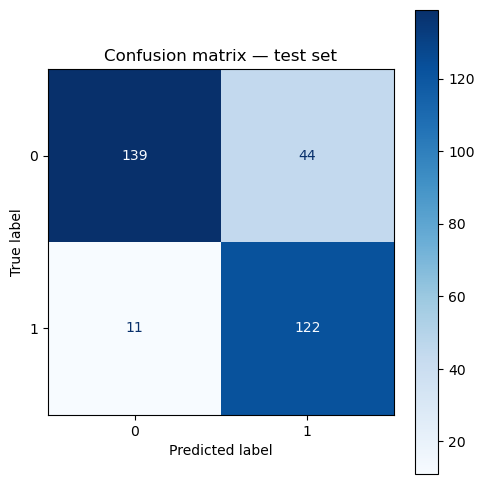

In [18]:
if t1 is not None:
    fig, ax = plt.subplots(figsize=(5, 5))
    ConfusionMatrixDisplay.from_predictions(y_test, test_pred, ax=ax, cmap="Blues")
    ax.set_title("Confusion matrix — test set")
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / "confusion_matrix_test.png", dpi=150)
    plt.show()


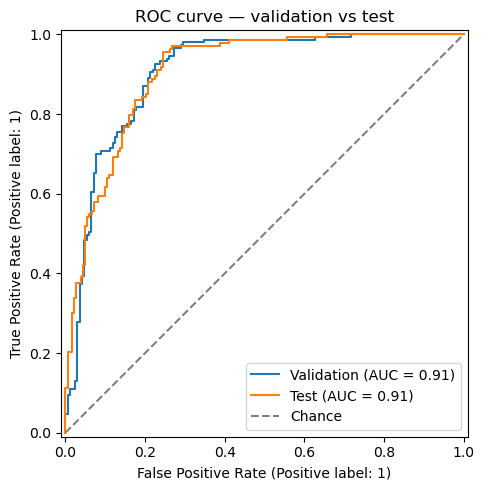

In [19]:
if t1 is not None:
    fig, ax = plt.subplots(figsize=(5, 5))
    RocCurveDisplay.from_predictions(y_val, val_proba, ax=ax, name="Validation")
    RocCurveDisplay.from_predictions(y_test, test_proba, ax=ax, name="Test")
    ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Chance")
    ax.set_title("ROC curve — validation vs test")
    ax.legend()
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / "roc_curve.png", dpi=150)
    plt.show()


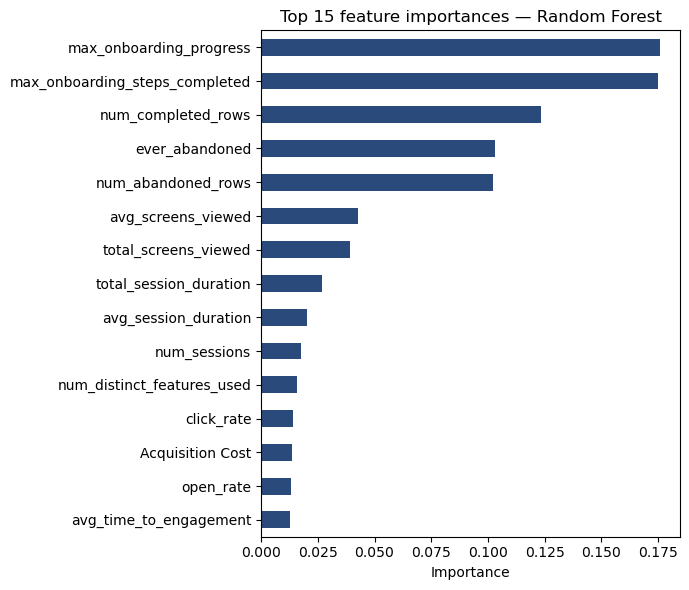

In [20]:
if t1 is not None:
    importances = pd.Series(model.feature_importances_, index=X_train.columns)
    top15 = importances.sort_values(ascending=False).head(15)

    fig, ax = plt.subplots(figsize=(7, 6))
    top15[::-1].plot(kind="barh", ax=ax, color="#2a4a7c")
    ax.set_title("Top 15 feature importances — Random Forest")
    ax.set_xlabel("Importance")
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / "feature_importance.png", dpi=150)
    plt.show()